# 09 Klasifikasi Biner

Dua kelas, misalnya hoaks atau bukan, toxic atau bukan. Contoh: ujaran kebencian di Twitter.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

ISI_SETELAH_EDA

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** target hanya dua kelas dan semua data latih berlabel. Metriknya biasanya F1 kelas
positif atau AUC. Kalau labelnya sedikit, pakai folder `08`.

**Yang perlu diganti kalau datanya beda:**
- `load_data`, `TEXT_COL`, `LABEL_COL`.
- `score_fn` di bagian 6 kalau metriknya lain. AUC tidak butuh threshold.
- `MODEL_RUNS` di config. `indobertweet` untuk media sosial, `indobert` untuk teks formal.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya TF-IDF, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
HOLDOUT_SHARE = 0.2
TEXT_COL, LABEL_COL = "Tweet", "HS"
MIN_GAIN = 0.002  # threshold hanya dipakai kalau skor OOF nested naik lebih dari ini

SETTINGS = {
    "cepat": {"folds": 3, "epochs": 3, "model_runs": [("indobertweet", SEED)]},
    "penuh": {
        "folds": 5,
        "epochs": 4,
        "model_runs": [("indobertweet", SEED), ("indobert", SEED), ("indobertweet", SEED + 1)],
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'folds': 5, 'epochs': 4, 'model_runs': [('indobertweet', 42), ('indobert', 42), ('indobertweet', 43)]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Metrik, interval noise, dan pencatat hasil.** Metrik diuji dulu pada contoh yang jawabannya
dihitung manual. `record` mencatat skor OOF dan skor holdout untuk tiap pendekatan.

In [6]:
from sklearn.metrics import f1_score  # noqa: E402
from sklearn.model_selection import StratifiedGroupKFold  # noqa: E402


def macro_f1(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


assert abs(macro_f1([0, 0, 1, 1], [0, 1, 1, 1]) - (2 / 3 + 0.8) / 2) < 1e-9


def bootstrap_interval(y_true, y_pred, score_fn=macro_f1, n_boot: int = 300) -> str:
    """Interval 95%. Selisih di dalam interval ini belum tentu perbaikan nyata."""
    rng = np.random.default_rng(SEED)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(y_true), len(y_true))
        scores.append(score_fn(y_true[pick], y_pred[pick]))
    return f"{np.percentile(scores, 2.5):.3f}-{np.percentile(scores, 97.5):.3f}"


def make_folds(target, groups, n_folds: int) -> np.ndarray:
    """StratifiedGroupKFold: duplikat tidak lintas fold, proporsi kelas terjaga."""
    splitter = StratifiedGroupKFold(n_folds, shuffle=True, random_state=SEED)
    folds = np.zeros(len(target), dtype=int)
    for fold, (_, val_idx) in enumerate(splitter.split(np.zeros(len(target)), target, groups)):
        folds[val_idx] = fold
    return folds


results: list[dict] = []


def record(name: str, oof_pred, holdout_pred, score_fn=macro_f1) -> None:
    """Catat skor OOF dan holdout. Holdout hanya untuk laporan, bukan untuk memilih model."""
    results.append(
        {
            "model": name,
            "oof": round(score_fn(y, oof_pred), 4),
            "oof_ci95": bootstrap_interval(y, oof_pred, score_fn),
            "holdout": round(score_fn(y_holdout, holdout_pred), 4),
        }
    )
    print(results[-1])

**Model dengan cross-validation.** `cv_tfidf` adalah baseline word dan char TF-IDF + regresi
logistik, sedangkan `cv_transformer` melatih tiap kombinasi model dan seed di semua fold. Hasilnya
probabilitas OOF dan rata-rata probabilitas holdout.

In [7]:
from scipy.sparse import hstack  # noqa: E402
from sklearn.multiclass import OneVsRestClassifier  # noqa: E402


def cv_tfidf(train_texts, target, holdout_texts, folds, multilabel=False):
    """Baseline TF-IDF. Vektorisasi difit di dalam fold supaya tidak bocor."""
    target = np.asarray(target)
    shape = target.shape[1] if multilabel else int(target.max()) + 1
    oof = np.zeros((len(target), shape))
    holdout = np.zeros((len(holdout_texts), shape))
    train_texts = pd.Series(list(train_texts))
    holdout_series = pd.Series(list(holdout_texts))
    for fold in np.unique(folds):
        fit, val = folds != fold, folds == fold
        word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)
        x_fit = hstack([word.fit_transform(train_texts[fit]), char.fit_transform(train_texts[fit])])
        base = LogisticRegression(C=3.0, max_iter=2000, class_weight="balanced")
        model = OneVsRestClassifier(base) if multilabel else base
        model.fit(x_fit.tocsr(), target[fit])
        for mask_texts, store, where in (
            (train_texts[val], oof, val),
            (holdout_series, holdout, None),
        ):
            x_pred = hstack([word.transform(mask_texts), char.transform(mask_texts)]).tocsr()
            probs = model.predict_proba(x_pred)
            if where is None:
                store += probs / len(np.unique(folds))
            else:
                store[where] = probs
    return oof, holdout


def cv_transformer(
    train_texts,
    target,
    holdout_texts,
    folds,
    model_runs,
    epochs,
    problem="ce",
    balanced=True,
    max_len=128,
):
    """Latih tiap (model, seed) di semua fold, lalu rata-ratakan probabilitasnya."""
    target = np.asarray(target)
    train_texts = np.array(list(train_texts), dtype=object)
    holdout_texts = list(holdout_texts)
    n_out = (
        target.shape[1] if problem == "bce" else (1 if problem == "mse" else int(target.max()) + 1)
    )
    oof = np.zeros((len(target), n_out))
    holdout = np.zeros((len(holdout_texts), n_out))
    n_folds = len(np.unique(folds))
    for model_name, seed in model_runs:
        for fold in range(n_folds):
            fit, val = folds != fold, folds == fold
            weights = None
            if problem == "ce" and balanced:
                weights = len(target[fit]) / (n_out * np.bincount(target[fit], minlength=n_out))
            elif problem == "bce" and balanced:
                positives = np.maximum(target[fit].sum(0), 1)
                weights = np.clip((len(target[fit]) - positives) / positives, 1, 20)
            pred_val, pred_hold = train_predict(
                model_name,
                train_texts[fit].tolist(),
                target[fit],
                [train_texts[val].tolist(), holdout_texts],
                problem=problem,
                num_labels=n_out if problem != "bce" else None,
                class_weights=weights,
                epochs=epochs,
                seed=seed + fold,
                max_len=max_len,
            )
            oof[val] += pred_val.reshape(val.sum(), -1) / len(model_runs)
            holdout += pred_hold.reshape(len(holdout_texts), -1) / (n_folds * len(model_runs))
    return oof, holdout

**Training transformer.** Satu fungsi untuk klasifikasi (`problem="ce"`), multi-label (`"bce"`),
dan regresi (`"mse"`). Loop-nya ditulis sendiri supaya mudah dibaca dan outputnya bersih.

In [8]:
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import (  # noqa: E402
    AutoModelForSequenceClassification,
    AutoTokenizer as _SeqTokenizer,
    get_linear_schedule_with_warmup,
)


def _encode(tokenizer, texts, pairs, max_len):
    args = (list(texts), list(pairs)) if pairs is not None else (list(texts),)
    tokens = tokenizer(
        *args, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
    )
    return tokens["input_ids"], tokens["attention_mask"]


def _loss_fn(problem, weights):
    if problem == "ce":
        return torch.nn.CrossEntropyLoss(weight=weights)
    # untuk multi-label, class_weights berperan sebagai pos_weight per label
    return (
        torch.nn.BCEWithLogitsLoss(pos_weight=weights) if problem == "bce" else torch.nn.MSELoss()
    )


def _to_output(logits, problem):
    if problem == "ce":
        return torch.softmax(logits.float(), dim=1)
    if problem == "bce":
        return torch.sigmoid(logits.float())
    return logits.float().squeeze(-1)


@torch.inference_mode()
def _predict(model, ids, mask, problem, batch_size):
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size].to(DEVICE)
        batch_mask = mask[start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(input_ids=batch_ids, attention_mask=batch_mask).logits
        chunks.append(_to_output(logits, problem).cpu())
    return torch.cat(chunks).numpy()


def train_predict(
    model_name,
    train_texts,
    train_y,
    predict_sets,
    problem="ce",
    num_labels=None,
    class_weights=None,
    train_pairs=None,
    epochs=3,
    lr=2e-5,
    batch_size=32,
    max_len=128,
    seed=42,
):
    """Latih satu model, lalu kembalikan prediksi untuk tiap set di predict_sets.

    predict_sets: daftar teks, atau daftar pasangan (teks, teks_pair) untuk tugas dua teks.
    """
    seed_everything(seed)
    tokenizer = _SeqTokenizer.from_pretrained(MODEL_DIR / model_name)
    num_labels = num_labels or (int(np.max(train_y)) + 1 if problem == "ce" else 1)
    if problem == "bce":
        num_labels = np.asarray(train_y).shape[1]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=num_labels, ignore_mismatched_sizes=True
    ).to(DEVICE)

    ids, mask = _encode(tokenizer, train_texts, train_pairs, max_len)
    target = torch.tensor(np.asarray(train_y), dtype=torch.long if problem == "ce" else torch.float)
    if problem == "mse":
        target = target.view(-1, 1)
    loader = DataLoader(
        TensorDataset(ids, mask, target),
        batch_size=batch_size,
        shuffle=True,
        drop_last=len(ids) > batch_size,
    )
    weights = (
        None if class_weights is None else torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    )
    loss_fn = _loss_fn(problem, weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = max(1, epochs * len(loader))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(
                    input_ids=batch_ids.to(DEVICE), attention_mask=batch_mask.to(DEVICE)
                ).logits
                loss = loss_fn(logits, batch_y.to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

    outputs = []
    for item in predict_sets:
        texts, pairs = item if isinstance(item, tuple) else (item, None)
        pred_ids, pred_mask = _encode(tokenizer, texts, pairs, max_len)
        outputs.append(_predict(model, pred_ids, pred_mask, problem, batch_size * 2))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs

**Fungsi gambar confusion matrix**, dipakai di bagian post-analysis.

In [9]:
from sklearn.metrics import confusion_matrix  # noqa: E402


def plot_confusion(y_true, y_pred, names, title="Confusion matrix") -> None:
    matrix = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(names))
    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=names,
        yticklabels=names,
        title=title,
        xlabel="prediksi",
        ylabel="asli",
    )
    ax.grid(False)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()

## 4. EDA

Muat data, lalu sisihkan holdout. Holdout berperan seperti test tersembunyi dan hanya dipakai untuk
laporan akhir.

In [10]:
from sklearn.metrics import roc_auc_score as auc_score  # noqa: E402
from sklearn.model_selection import train_test_split  # noqa: E402


def load_data() -> pd.DataFrame:
    frame = pd.read_csv(find_file("data.csv"), encoding="latin-1")
    frame = frame.sample(n=min(N_ROWS, len(frame)), random_state=SEED).reset_index(drop=True)
    return frame[[TEXT_COL, LABEL_COL]]


data = load_data()
train, holdout = train_test_split(
    data, test_size=HOLDOUT_SHARE, stratify=data[LABEL_COL], random_state=SEED
)
train, holdout = train.reset_index(drop=True), holdout.reset_index(drop=True)
print(f"latih={len(train)} | holdout={len(holdout)}")
print("proporsi positif:", round(train[LABEL_COL].mean(), 3))
text_profile(train[TEXT_COL])

latih=4000 | holdout=1000
proporsi positif: 0.417


baris                4000.0
kosong                  0.0
duplikat_persis_%       0.5
kata_median            15.0
kata_p95               38.0
kata_maks              49.0
ada_url_%               0.0
ada_emoji_%             0.0
dtype: float64

Token khusus yang sering muncul, dan beda panjang teks antar kelas.

persen baris berisi token khusus: {'USER': np.float64(57.7), 'RT': np.float64(6.6), 'URL': np.float64(5.6)}


AUC adversarial latih vs holdout: 0.48


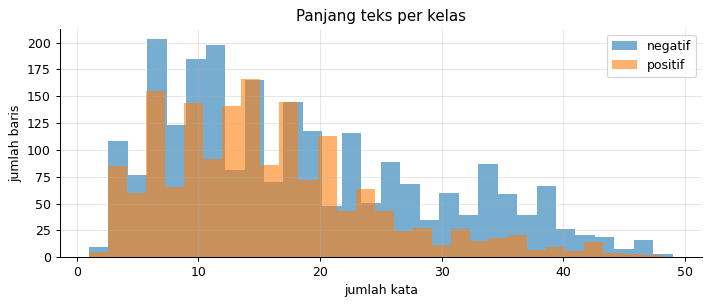

In [11]:
token_share = {
    t: round(100 * train[TEXT_COL].str.contains(rf"\b{t}\b").mean(), 1)
    for t in ["USER", "RT", "URL"]
}
print("persen baris berisi token khusus:", token_share)
print(
    "AUC adversarial latih vs holdout:",
    round(adversarial_auc(train[TEXT_COL], holdout[TEXT_COL]), 3),
)

lengths = train[TEXT_COL].str.split().str.len().clip(upper=60)
fig, ax = plt.subplots()
for value, name in ((0, "negatif"), (1, "positif")):
    lengths[train[LABEL_COL] == value].plot.hist(bins=30, alpha=0.6, ax=ax, label=name)
ax.set(title="Panjang teks per kelas", xlabel="jumlah kata", ylabel="jumlah baris")
ax.legend()
plt.tight_layout()
plt.show()

**Temuan dan keputusan**

ISI_SETELAH_EDA

## 5. Preprocessing

Token `USER`, `RT`, dan `URL` dibuang karena hanya sisa anonimisasi. Kata kasar dan emoji tetap
dipertahankan karena justru menjadi sinyal utama. Tanda baca tidak dibuang.

In [12]:
TOKEN_RE = re.compile(r"\b(USER|RT|URL)\b|\\n")
BYTES_RE = re.compile(r"(?:\\x[0-9a-f]{2})+")


def decode_bytes(match: re.Match) -> str:
    """Data ini menyimpan emoji sebagai teks byte, misalnya \\xf0\\x9f\\x98\\xa0. Kembalikan jadi emoji."""
    return " " + bytes.fromhex(match.group(0).replace("\\x", "")).decode("utf-8", "ignore") + " "


def preprocess(text: str) -> str:
    return clean_text(TOKEN_RE.sub(" ", BYTES_RE.sub(decode_bytes, str(text))))


train["clean"] = train[TEXT_COL].map(preprocess)
holdout["clean"] = holdout[TEXT_COL].map(preprocess)
train["group"] = near_duplicate_groups(train["clean"].tolist())
y = train[LABEL_COL].to_numpy()
y_holdout = holdout[LABEL_COL].to_numpy()
print(f"grup near-duplicate: {train['group'].nunique()} dari {len(train)} baris")

grup near-duplicate: 3951 dari 4000 baris


## 6. Validasi

Skema `StratifiedGroupKFold`. Metrik utama F1 kelas positif, dan AUC ikut dilaporkan karena tidak
bergantung pada threshold.

In [13]:
def f1_positive(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="binary", zero_division=0))


assert abs(f1_positive([0, 1, 1, 1], [0, 1, 1, 0]) - 0.8) < 1e-9

folds = make_folds(y, train["group"], SETTINGS["folds"])
print(pd.crosstab(folds, y))

col_0    0    1
row_0          
0      466  337
1      458  335
2      478  320
3      463  343
4      468  332


## 7. Baseline

Tebak semua positif, lalu TF-IDF + regresi logistik.

In [14]:
record("semua_positif", np.ones(len(y), dtype=int), np.ones(len(y_holdout), dtype=int), f1_positive)
with stage("baseline_tfidf"):
    oof_tfidf, hold_tfidf = cv_tfidf(train["clean"], y, holdout["clean"], folds)
record("tfidf_lr", oof_tfidf.argmax(1), hold_tfidf.argmax(1), f1_positive)
print("AUC OOF tfidf:", round(auc_score(y, oof_tfidf[:, 1]), 4))

{'model': 'semua_positif', 'oof': 0.5883, 'oof_ci95': '0.574-0.603', 'holdout': 0.5886}


[waktu] baseline_tfidf: 7 detik


{'model': 'tfidf_lr', 'oof': 0.7965, 'oof_ci95': '0.781-0.809', 'holdout': 0.8132}
AUC OOF tfidf: 0.9132


## 8. Model Utama

Transformer dengan cross-validation. Kalau `USE_PRETRAINED=False`, model utama sama dengan baseline.

In [15]:
with stage("transformer"):
    if USE_PRETRAINED:
        oof_main, hold_main = cv_transformer(
            train["clean"], y, holdout["clean"], folds, SETTINGS["model_runs"], SETTINGS["epochs"]
        )
    else:
        oof_main, hold_main = oof_tfidf, hold_tfidf
record("model_utama", oof_main.argmax(1), hold_main.argmax(1), f1_positive)
print("AUC OOF model utama:", round(auc_score(y, oof_main[:, 1]), 4))

[waktu] transformer: 1265 detik


{'model': 'model_utama', 'oof': 0.8629, 'oof_ci95': '0.851-0.875', 'holdout': 0.8754}
AUC OOF model utama: 0.9529


## 9. Post-processing

Threshold untuk F1. Skor OOF dihitung nested: threshold tiap fold difit dari fold lain. Threshold
untuk holdout difit dari seluruh OOF, dan hanya dipakai kalau skor nested naik lebih dari `MIN_GAIN`.

In [16]:
def best_threshold(scores: np.ndarray, target: np.ndarray) -> float:
    grid = np.arange(0.1, 0.91, 0.01)
    values = [f1_positive(target, scores >= t) for t in grid]
    return float(grid[int(np.argmax(values))])


scores = oof_main[:, 1]
nested_pred = np.zeros(len(y), dtype=int)
for fold in np.unique(folds):
    fit = folds != fold
    nested_pred[~fit] = scores[~fit] >= best_threshold(scores[fit], y[fit])
threshold = best_threshold(scores, y)
hold_threshold = (hold_main[:, 1] >= threshold).astype(int)
record("model_utama_plus_threshold", nested_pred, hold_threshold, f1_positive)

use_threshold = f1_positive(y, nested_pred) > f1_positive(y, oof_main.argmax(1)) + MIN_GAIN
oof_decision = nested_pred if use_threshold else oof_main.argmax(1)
hold_pred = hold_threshold if use_threshold else hold_main.argmax(1)
print(f"threshold {threshold:.2f} -> dipakai: {use_threshold}")

{'model': 'model_utama_plus_threshold', 'oof': 0.8633, 'oof_ci95': '0.852-0.875', 'holdout': 0.8771}
threshold 0.47 -> dipakai: False


## 10. Post-analysis

**Tabel perbandingan.**

In [17]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,oof,oof_ci95,holdout
0,semua_positif,0.5883,0.574-0.603,0.5886
1,tfidf_lr,0.7965,0.781-0.809,0.8132
2,model_utama,0.8629,0.851-0.875,0.8754
3,model_utama_plus_threshold,0.8633,0.852-0.875,0.8771


**Confusion matrix OOF.**

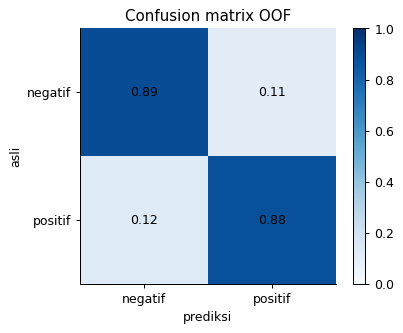

In [18]:
plot_confusion(y, oof_decision, ["negatif", "positif"], "Confusion matrix OOF")

**Salah prediksi paling yakin.** Di sini biasanya kelihatan label yang meragukan atau kata kasar yang
tidak bermaksud menyerang.

In [19]:
errors = train.assign(prediksi=oof_decision, skor=scores.round(3))
errors = errors[errors[LABEL_COL] != errors["prediksi"]]
errors["yakin"] = (errors["skor"] - 0.5).abs()
errors.sort_values("yakin", ascending=False)[["clean", LABEL_COL, "skor"]].head(8)

,clean,HS,skor
1419,bangsad salah. gilak.',0,0.998
347,sekarang yang gembel gembel twitter dan whatsapp chat gak jelas di whatsapp langsung b...,0,0.997
2008,iyaa komunitas muslim &amp; budha bareng2 sediain makanan buat rescuers nya jg. di saa...,1,0.003
1655,bentar bentar kunyuk mirip siapa yak *mikir keras*',1,0.003
56,1. bangsat 2. cebong 3. kecoak 4. bajingan 5. taik ayam 6. uanjing 7. bodat 8. cecurut...,0,0.997
853,: dasar bajingan! 😠,0,0.997
2616,ahok versi pakpahan .. trims kepada semua pihak yg udah ciduk bajingan ini,0,0.997
1073,pasti cebong ikut2 an gelas nya ada gambar 5 priode cebong 😂😂😂 ',0,0.997


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [20]:
pd.DataFrame({"id": holdout.index, "label": hold_pred}).to_csv(
    RESULT_DIR / "submission.csv", index=False
)
pd.DataFrame({"skor": scores, "fold": folds, "y": y}).to_csv(RESULT_DIR / "oof.csv", index=False)
run_summary(
    "biner",
    len(data),
    {r["model"]: {"oof": r["oof"], "holdout": r["holdout"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=biner mode=penuh n_rows=5000 total_detik=1292 gpu=True
{
 "semua_positif": {
  "oof": 0.5883,
  "holdout": 0.5886
 },
 "tfidf_lr": {
  "oof": 0.7965,
  "holdout": 0.8132
 },
 "model_utama": {
  "oof": 0.8629,
  "holdout": 0.8754
 },
 "model_utama_plus_threshold": {
  "oof": 0.8633,
  "holdout": 0.8771
 }
}


**Poin untuk presentasi**

ISI_SETELAH_EDA